In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root and dataset
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "ml-latest-small"

ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")

print("Dataset loaded successfully!")
print(f"Ratings: {ratings.shape}")
print(f"Movies: {movies.shape}")
print(f"Tags: {tags.shape}")

display(ratings.head())
display(movies.head())

Dataset loaded successfully!
Ratings: (100836, 4)
Movies: (9742, 3)
Tags: (3683, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [2]:
print("Missing values:")
print(ratings.isnull().sum())

print("\nDuplicate user-movie ratings:")
print(ratings.duplicated(["userId", "movieId"]).sum())

print("\nUnique users:", ratings["userId"].nunique())
print("Unique movies rated:", ratings["movieId"].nunique())
print("Rating range:", ratings["rating"].min(), "-", ratings["rating"].max())

print("\nRatings per user:")
display(ratings.groupby("userId")["rating"].count().describe())

print("\nMost-rated movies:")
movie_popularity = (
    ratings.groupby("movieId")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("rating_count")
    .reset_index()
    .merge(movies, on="movieId")
)

display(movie_popularity[["title", "rating_count"]])

Missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate user-movie ratings:
0

Unique users: 610
Unique movies rated: 9724
Rating range: 0.5 - 5.0

Ratings per user:


count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
Name: rating, dtype: float64


Most-rated movies:


,title,rating_count
0,Forrest Gump (1994),329
1,"Shawshank Redemption, The (1994)",317
2,Pulp Fiction (1994),307
3,"Silence of the Lambs, The (1991)",279
4,"Matrix, The (1999)",278
5,Star Wars: Episode IV - A New Hope (1977),251
6,Jurassic Park (1993),238
7,Braveheart (1995),237
8,Terminator 2: Judgment Day (1991),224
9,Schindler's List (1993),220


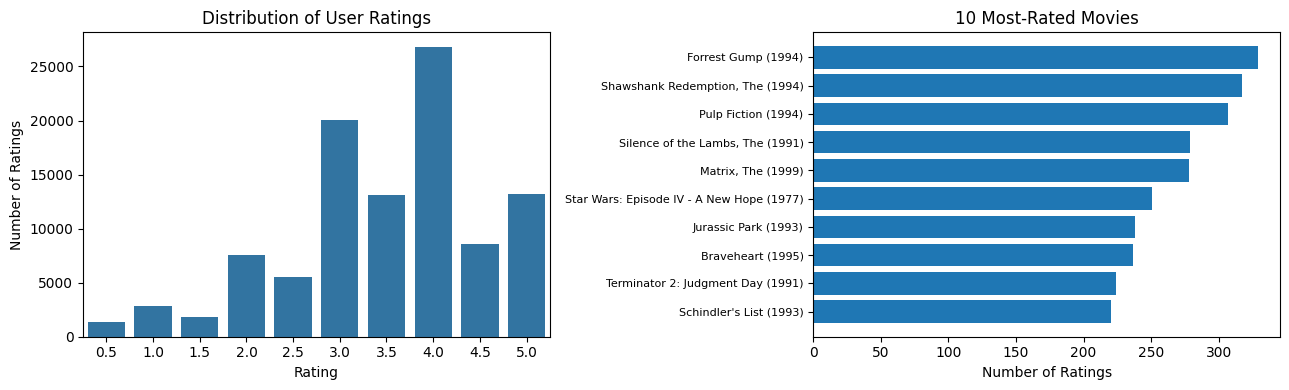

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=ratings, x="rating", ax=axes[0])
axes[0].set_title("Distribution of User Ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of Ratings")

top_movies = movie_popularity.sort_values("rating_count")
axes[1].barh(top_movies["title"], top_movies["rating_count"])
axes[1].set_title("10 Most-Rated Movies")
axes[1].set_xlabel("Number of Ratings")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()